# Loan Approval Prediction System

### MongoDB and Machine Learning Project

**Technologies:**
- Python
- MongoDB
- PyMongo
- Pandas
- Scikit-learn
- Matplotlib
- Seaborn

**Machine Learning Models:**
1. Logistic Regression
2. Linear Regression

**Dataset:** Loan Approval Classification Dataset
**Records:** 45,000

In [1]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pymongo import MongoClient

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:

# Load the dataset

df = pd.read_csv("data/loan_data.csv")

# Display first 5 records
df.head()


,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [3]:

# Check number of rows and columns

print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])


Total Records: 45000
Total Columns: 14


In [4]:

# Display column names
print("Column Names:")
print(df.columns.tolist())

# Display data types
print("\nData Types:")
print(df.dtypes)


Column Names:
['person_age', 'person_gender', 'person_education', 'person_income', 'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file', 'loan_status']

Data Types:
person_age                        float64
person_gender                         str
person_education                      str
person_income                     float64
person_emp_exp                      int64
person_home_ownership                 str
loan_amnt                         float64
loan_intent                           str
loan_int_rate                     float64
loan_percent_income               float64
cb_person_cred_hist_length        float64
credit_score                        int64
previous_loan_defaults_on_file        str
loan_status                         int64
dtype: object


In [5]:

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())


Missing Values:
person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64

Duplicate Records: 0


loan_status
0    35000
1    10000
Name: count, dtype: int64


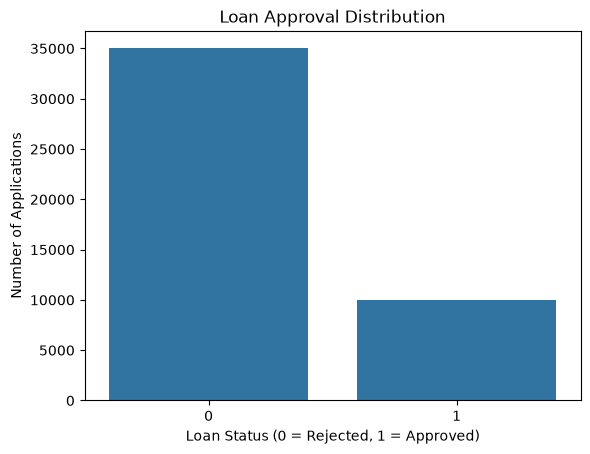

In [6]:

# Count approved and rejected applications

print(df["loan_status"].value_counts())

# Visualize loan status
sns.countplot(data=df, x="loan_status")

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status (0 = Rejected, 1 = Approved)")
plt.ylabel("Number of Applications")

plt.show()


# 5. MongoDB Connection

Connecting Python with MongoDB using PyMongo.

In [7]:

# Connect to MongoDB

from pymongo import MongoClient

# Establish connection
client = MongoClient("mongodb://localhost:27017/")

# Verify connection
try:
    client.admin.command("ping")
    print("MongoDB Connected Successfully!")

except Exception as e:
    print("MongoDB Connection Failed:", e)


MongoDB Connected Successfully!


In [8]:

# Select database
db = client["loan_approval_db"]

# Select collection
collection = db["loan_applications"]

print("Database:", db.name)
print("Collection:", collection.name)


Database: loan_approval_db
Collection: loan_applications


# 6. Insert Dataset into MongoDB

Importing all loan application records into MongoDB using PyMongo.

In [9]:

import json

# Check whether collection already contains data
existing_count = collection.count_documents({})

if existing_count == 0:

    # Convert DataFrame into MongoDB documents
    records = json.loads(df.to_json(orient="records"))

    # Insert records
    result = collection.insert_many(records)

    print("Data inserted successfully!")
    print("Inserted records:", len(result.inserted_ids))

else:
    print("Collection already contains data.")
    print("Existing records:", existing_count)


Data inserted successfully!
Inserted records: 45000


In [10]:

# Verify MongoDB records

total_records = collection.count_documents({})

print("Total documents in MongoDB:", total_records)

# Display one sample document
sample = collection.find_one({}, {"_id": 0})

print("\nSample Document:")
print(sample)


Total documents in MongoDB: 45000

Sample Document:
{'person_age': 22.0, 'person_gender': 'female', 'person_education': 'Master', 'person_income': 71948.0, 'person_emp_exp': 0, 'person_home_ownership': 'RENT', 'loan_amnt': 35000.0, 'loan_intent': 'PERSONAL', 'loan_int_rate': 16.02, 'loan_percent_income': 0.49, 'cb_person_cred_hist_length': 3.0, 'credit_score': 561, 'previous_loan_defaults_on_file': 'No', 'loan_status': 1}


# 7. Fetch Data from MongoDB

Retrieving loan application records using PyMongo.

In [11]:

# Fetch all records from MongoDB

mongo_data = list(collection.find({}, {"_id": 0}))

# Convert into DataFrame
df = pd.DataFrame(mongo_data)

print("Records fetched:", len(df))
print("Columns:", len(df.columns))

df.head()


Records fetched: 45000
Columns: 14


,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [12]:

# Statistical summary of numerical columns

df.describe()


,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status
count,45000.000000,4.500000e+04,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000
mean,27.764178,8.031905e+04,5.410333,9583.157556,11.006606,0.139725,5.867489,632.608756,0.222222
std,6.045108,8.042250e+04,6.063532,6314.886691,2.978808,0.087212,3.879702,50.435865,0.415744
min,20.000000,8.000000e+03,0.000000,500.000000,5.420000,0.000000,2.000000,390.000000,0.000000
25%,24.000000,4.720400e+04,1.000000,5000.000000,8.590000,0.070000,3.000000,601.000000,0.000000
50%,26.000000,6.704800e+04,4.000000,8000.000000,11.010000,0.120000,4.000000,640.000000,0.000000
75%,30.000000,9.578925e+04,8.000000,12237.250000,12.990000,0.190000,8.000000,670.000000,0.000000
max,144.000000,7.200766e+06,125.000000,35000.000000,20.000000,0.660000,30.000000,850.000000,1.000000


In [13]:

# Display unique values in categorical columns

categorical_columns = df.select_dtypes(
    include="object"
).columns

for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts())



 person_gender
person_gender
male      24841
female    20159
Name: count, dtype: int64

 person_education
person_education
Bachelor       13399
Associate      12028
High School    11972
Master          6980
Doctorate        621
Name: count, dtype: int64

 person_home_ownership
person_home_ownership
RENT        23443
MORTGAGE    18489
OWN          2951
OTHER         117
Name: count, dtype: int64

 loan_intent
loan_intent
EDUCATION            9153
MEDICAL              8548
VENTURE              7819
PERSONAL             7552
DEBTCONSOLIDATION    7145
HOMEIMPROVEMENT      4783
Name: count, dtype: int64

 previous_loan_defaults_on_file
previous_loan_defaults_on_file
Yes    22858
No     22142
Name: count, dtype: int64


C:\Users\rahul\AppData\Local\Temp\ipykernel_5520\1512681256.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [14]:

# Check minimum and maximum values

columns_to_check = [
    "person_age",
    "person_income",
    "person_emp_exp",
    "loan_amnt",
    "loan_int_rate",
    "credit_score"
]

for col in columns_to_check:
    print(
        col,
        "Minimum:", df[col].min(),
        "Maximum:", df[col].max()
    )


person_age Minimum: 20.0 Maximum: 144.0
person_income Minimum: 8000.0 Maximum: 7200766.0
person_emp_exp Minimum: 0 Maximum: 125
loan_amnt Minimum: 500.0 Maximum: 35000.0
loan_int_rate Minimum: 5.42 Maximum: 20.0
credit_score Minimum: 390 Maximum: 850


In [18]:

# Find unrealistic applicant ages
print("Applicants with age above 100:")
print(df[df["person_age"] > 100][
    ["person_age", "person_income", "credit_score"]
].head(10))

# Find unrealistic employment experience
print("\nApplicants with employment experience greater than age minus 18:")
print(df[df["person_emp_exp"] > df["person_age"] - 18][
    ["person_age", "person_emp_exp"]
].head(10))

# Check extreme annual incomes
print("\nHighest annual incomes:")
print(df["person_income"].nlargest(10))


Applicants with age above 100:
       person_age  person_income  credit_score
81          144.0       300616.0           789
183         144.0       241424.0           807
575         123.0        97140.0           805
747         123.0        94723.0           714
32297       144.0      7200766.0           850
37930       116.0      5545545.0           708
38113       109.0      5556399.0           792

Applicants with employment experience greater than age minus 18:
Empty DataFrame
Columns: [person_age, person_emp_exp]
Index: []

Highest annual incomes:
32297    7200766.0
38113    5556399.0
37930    5545545.0
30049    2448661.0
32546    2280980.0
32497    2139143.0
37175    2012954.0
41288    1741243.0
31924    1728974.0
35850    1661567.0
Name: person_income, dtype: float64


count    4.500000e+04
mean     8.031905e+04
std      8.042250e+04
min      8.000000e+03
25%      4.720400e+04
50%      6.704800e+04
75%      9.578925e+04
90%      1.332761e+05
95%      1.667547e+05
99%      2.714501e+05
max      7.200766e+06
Name: person_income, dtype: float64


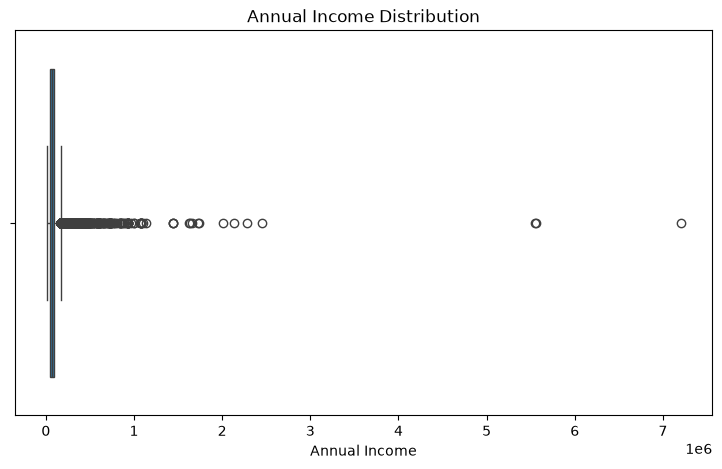

In [19]:

# Check income percentiles

print(df["person_income"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

# Visualize income distribution
plt.figure(figsize=(9, 5))

sns.boxplot(x=df["person_income"])

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income")

plt.show()


# 8. Data Cleaning and Preprocessing

Removing invalid applicant ages and transforming skewed income values.

In [20]:

# Create a separate cleaned DataFrame
df_clean = df.copy()

# Count records before cleaning
before_cleaning = len(df_clean)

# Remove applicants older than 100
df_clean = df_clean[df_clean["person_age"] <= 100].copy()

# Count records after cleaning
after_cleaning = len(df_clean)

print("Records before cleaning:", before_cleaning)
print("Records after cleaning:", after_cleaning)
print("Records removed:", before_cleaning - after_cleaning)


Records before cleaning: 45000
Records after cleaning: 44993
Records removed: 7


In [21]:

# Apply logarithmic transformation

df_clean["log_person_income"] = np.log1p(
    df_clean["person_income"]
)

print("Original Income:")
print(df_clean["person_income"].describe())

print("\nTransformed Income:")
print(df_clean["log_person_income"].describe())


Original Income:
count    4.499300e+04
mean     7.990845e+04
std      6.332213e+04
min      8.000000e+03
25%      4.719500e+04
50%      6.704600e+04
75%      9.577800e+04
max      2.448661e+06
Name: person_income, dtype: float64

Transformed Income:
count    44993.000000
mean        11.122080
std          0.556255
min          8.987322
25%         10.762064
50%         11.113149
75%         11.469799
max         14.711052
Name: log_person_income, dtype: float64


In [22]:

# Check final dataset

print("Final Records:", len(df_clean))

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nAge Range:")
print(df_clean["person_age"].min(),
      "to",
      df_clean["person_age"].max())

print("\nDuplicate Records:",
      df_clean.duplicated().sum())

df_clean.head()


Final Records: 44993

Missing Values:
person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
log_person_income                 0
dtype: int64

Age Range:
20.0 to 94.0

Duplicate Records: 0


,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status,log_person_income
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1,11.183713
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0,9.415971
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1,9.428592
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1,11.286702
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1,11.099469


# 9. Feature Selection and Encoding

Selecting relevant input features and separating the target variable.

In [23]:

# Select numerical features
numerical_features = [
    "person_age",
    "log_person_income",
    "person_emp_exp",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "credit_score"
]

# Select categorical features
categorical_features = [
    "person_gender",
    "person_education",
    "person_home_ownership",
    "loan_intent",
    "previous_loan_defaults_on_file"
]

# Combine features
X = df_clean[numerical_features + categorical_features]

# Target variable
y = df_clean["loan_status"]

print("Features:", X.shape)
print("Target:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())


Features: (44993, 13)
Target: (44993,)

Target Distribution:
loan_status
0    34993
1    10000
Name: count, dtype: int64


In [24]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [25]:

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training records: 35994
Testing records: 8999

Training target distribution:
loan_status
0    27994
1     8000
Name: count, dtype: int64

Testing target distribution:
loan_status
0    6999
1    2000
Name: count, dtype: int64


In [26]:

# Create Logistic Regression pipeline

logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train model
logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")


Logistic Regression Model Trained Successfully!


In [27]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict test data
y_pred = logistic_model.predict(X_test)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy : 0.8522
Precision: 0.6108
Recall   : 0.9235
F1 Score : 0.7353

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.83      0.90      6999
           1       0.61      0.92      0.74      2000

    accuracy                           0.85      8999
   macro avg       0.79      0.88      0.82      8999
weighted avg       0.89      0.85      0.86      8999



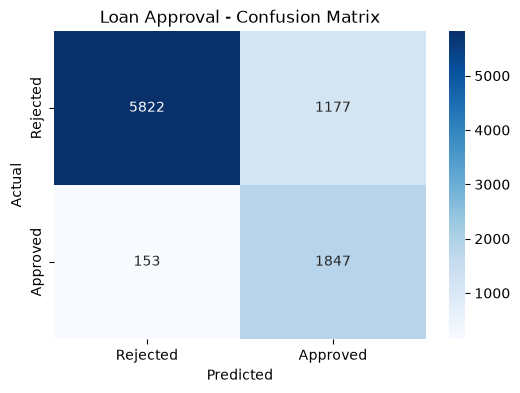

In [28]:

# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Loan Approval - Confusion Matrix")

plt.show()


# 10. Classification Model Comparison

Training Decision Tree and Random Forest classifiers
to compare their performance with Logistic Regression.

In [29]:

from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
decision_tree_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=12,
        class_weight="balanced",
        random_state=42
    ))
])

# Train model
decision_tree_model.fit(X_train, y_train)

# Make predictions
dt_pred = decision_tree_model.predict(X_test)

# Evaluate
print("DECISION TREE RESULTS")
print("---------------------")
print("Accuracy :", round(accuracy_score(y_test, dt_pred), 4))
print("Precision:", round(precision_score(y_test, dt_pred), 4))
print("Recall   :", round(recall_score(y_test, dt_pred), 4))
print("F1 Score :", round(f1_score(y_test, dt_pred), 4))


DECISION TREE RESULTS
---------------------
Accuracy : 0.8887
Precision: 0.6998
Recall   : 0.874
F1 Score : 0.7772


In [30]:

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
random_forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
random_forest_model.fit(X_train, y_train)

# Make predictions
rf_pred = random_forest_model.predict(X_test)

# Evaluate
print("RANDOM FOREST RESULTS")
print("---------------------")
print("Accuracy :", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred), 4))
print("Recall   :", round(recall_score(y_test, rf_pred), 4))
print("F1 Score :", round(f1_score(y_test, rf_pred), 4))


RANDOM FOREST RESULTS
---------------------
Accuracy : 0.9035
Precision: 0.7306
Recall   : 0.8965
F1 Score : 0.8051


In [31]:

# Compare all classification models

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, dt_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred)
    ]
})

comparison = comparison.round(4)

print(comparison)


                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.8522     0.6108  0.9235    0.7353
1        Decision Tree    0.8887     0.6998  0.8740    0.7772
2        Random Forest    0.9035     0.7306  0.8965    0.8051


# 11. Save the Best Classification Model

In [32]:

import joblib
import os

# Create models directory if it doesn't exist
os.makedirs("models", exist_ok=True)

# Save Random Forest pipeline
joblib.dump(
    random_forest_model,
    "models/best_loan_approval_model.pkl"
)

print("Random Forest model saved successfully!")
print("Location: models/best_loan_approval_model.pkl")


Random Forest model saved successfully!
Location: models/best_loan_approval_model.pkl


In [33]:
# Load saved model
loaded_model = joblib.load(
    "models/best_loan_approval_model.pkl"
)

print("Model loaded successfully!")

# Test loaded model
loaded_predictions = loaded_model.predict(X_test)

print(
    "Loaded Model Accuracy:",
    round(accuracy_score(y_test, loaded_predictions), 4)
)

Model loaded successfully!
Loaded Model Accuracy: 0.9035


# 12. Generate Predictions and Store in MongoDB

In [34]:
# Generate predictions using Random Forest
rf_predictions = random_forest_model.predict(X_test)

# Create predictions DataFrame
predictions_df = X_test.copy()

predictions_df["actual_loan_status"] = y_test.values
predictions_df["predicted_loan_status"] = rf_predictions

# Convert predictions into MongoDB records
prediction_records = predictions_df.to_dict("records")

# Connect to MongoDB
client = MongoClient("mongodb://localhost:27017/")

db = client["loan_approval_db"]

# Select collection
predictions_collection = db["loan_predictions"]

# Clear old predictions (if any)
predictions_collection.delete_many({})

# Insert new predictions
result = predictions_collection.insert_many(prediction_records)

print("Predictions generated successfully!")
print("Total predictions stored:", len(result.inserted_ids))
print("MongoDB Collection: loan_predictions")

Predictions generated successfully!
Total predictions stored: 8999
MongoDB Collection: loan_predictions


In [35]:
# Verify stored predictions
print("Total documents:",
      predictions_collection.count_documents({}))

# Display first 5 predictions
for record in predictions_collection.find().limit(5):
    print(record)

Total documents: 8999
{'_id': ObjectId('6ae4b343ffa3a1acbddfad3d'), 'person_age': 24.0, 'log_person_income': 11.521905027750805, 'person_emp_exp': 5, 'loan_amnt': 5000.0, 'loan_int_rate': 16.35, 'loan_percent_income': 0.05, 'cb_person_cred_hist_length': 3.0, 'credit_score': 602, 'person_gender': 'male', 'person_education': 'Master', 'person_home_ownership': 'RENT', 'loan_intent': 'HOMEIMPROVEMENT', 'previous_loan_defaults_on_file': 'No', 'actual_loan_status': 0, 'predicted_loan_status': 1}
{'_id': ObjectId('6ae4b343ffa3a1acbddfad3e'), 'person_age': 34.0, 'log_person_income': 11.478344372113902, 'person_emp_exp': 15, 'loan_amnt': 5000.0, 'loan_int_rate': 6.17, 'loan_percent_income': 0.05, 'cb_person_cred_hist_length': 10.0, 'credit_score': 614, 'person_gender': 'male', 'person_education': 'Associate', 'person_home_ownership': 'RENT', 'loan_intent': 'HOMEIMPROVEMENT', 'previous_loan_defaults_on_file': 'Yes', 'actual_loan_status': 0, 'predicted_loan_status': 0}
{'_id': ObjectId('6ae4b343f

# 13. Analyze Predictions Using MongoDB Aggregation

In [36]:
# Count actual and predicted loan statuses
pipeline = [
    {
        "$group": {
            "_id": {
                "actual": "$actual_loan_status",
                "predicted": "$predicted_loan_status"
            },
            "total": {"$sum": 1}
        }
    },
    {
        "$sort": {"_id.actual": 1, "_id.predicted": 1}
    }
]

results = list(predictions_collection.aggregate(pipeline))

print("LOAN PREDICTION ANALYSIS")
print("------------------------")

for record in results:
    print(record)

LOAN PREDICTION ANALYSIS
------------------------
{'_id': {'actual': 0, 'predicted': 0}, 'total': 6338}
{'_id': {'actual': 0, 'predicted': 1}, 'total': 661}
{'_id': {'actual': 1, 'predicted': 0}, 'total': 207}
{'_id': {'actual': 1, 'predicted': 1}, 'total': 1793}


# 14. Loan Approval Summary Using MongoDB

In [37]:
# Aggregate predicted loan status

pipeline = [
    {
        "$group": {
            "_id": "$predicted_loan_status",
            "total_applicants": {"$sum": 1}
        }
    },
    {
        "$sort": {"_id": 1}
    }
]

summary = list(predictions_collection.aggregate(pipeline))

print("LOAN APPROVAL SUMMARY")
print("---------------------")

for item in summary:
    status = "Approved" if item["_id"] == 1 else "Rejected"

    print(status, ":", item["total_applicants"])

LOAN APPROVAL SUMMARY
---------------------
Rejected : 6545
Approved : 2454


# 15. Loan Prediction Visualizations

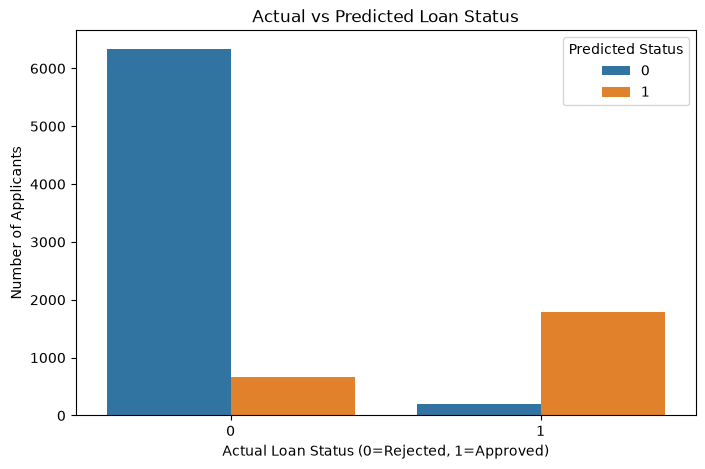

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Actual vs Predicted comparison
comparison_data = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": rf_predictions
})

plt.figure(figsize=(8, 5))

sns.countplot(
    data=comparison_data,
    x="Actual",
    hue="Predicted"
)

plt.title("Actual vs Predicted Loan Status")
plt.xlabel("Actual Loan Status (0=Rejected, 1=Approved)")
plt.ylabel("Number of Applicants")
plt.legend(title="Predicted Status")

plt.show()

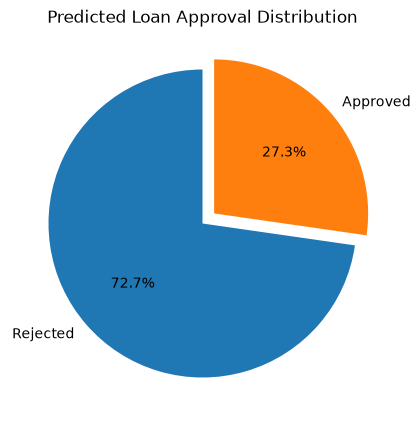

In [39]:
# Loan approval distribution

status_counts = pd.Series(rf_predictions).value_counts().sort_index()

labels = ["Rejected", "Approved"]
values = [
    status_counts.get(0, 0),
    status_counts.get(1, 0)
]

plt.figure(figsize=(7, 5))

plt.pie(
    values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    explode=(0, 0.1)
)

plt.title("Predicted Loan Approval Distribution")

plt.show()

# 17. Save Model Evaluation Results

In [40]:
# Save model comparison results

comparison.to_csv(
    "results/model_comparison.csv",
    index=False
)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


In [41]:
import os

for folder in ["data", "models", "results"]:
    print(f"\n{folder.upper()} FOLDER:")
    for file in os.listdir(folder):
        print("-", file)


DATA FOLDER:
- loan_data.csv

MODELS FOLDER:
- best_loan_approval_model.pkl

RESULTS FOLDER:
- model_comparison.csv


In [ ]:
# Verify the saved ML model

import os

model_path = "models/best_loan_approval_model.pkl"

if os.path.exists(model_path):
    print("Model exists!")
    print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")
else:
    print("Model not found!")

Model exists!
File size: 20205.1 KB


In [ ]:
# Final model loading test

import joblib

# Load saved model
model = joblib.load(
    "models/best_loan_approval_model.pkl"
)

# Make predictions
test_predictions = model.predict(X_test)

print("Model loaded successfully!")
print("Total predictions:", len(test_predictions))
print("First 10 predictions:", test_predictions[:10])

Model loaded successfully!
Total predictions: 8999
First 10 predictions: [1 0 0 0 0 0 1 0 0 0]
